# **Bài 1**

--- BÀI 1.1: HỒI QUY ĐƠN GIẢN ---
Hệ số chặn (Intercept): 787.44
Hệ số góc (Slope): 31.51
MSE: 26396.10
R2 Score: 0.9909


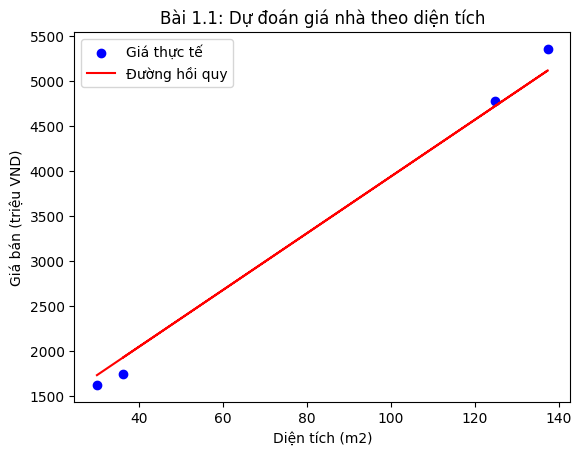

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tạo dữ liệu giả định cơ bản (20 căn nhà)
np.random.seed(42)
dien_tich = np.linspace(30, 150, 20).reshape(-1, 1)  # Diện tích từ 30m2 đến 150m2
# Giả sử công thức thực tế: Giá = 500 + 35 * Diện_tích + nhiễu nhỏ
gia_ban = 500 + 35 * dien_tich + np.random.normal(0, 150, size=(20, 1))

# Chia tập huấn luyện (80%) và kiểm tra (20%)
X_train, X_test, y_train, y_test = train_test_split(dien_tich, gia_ban, test_size=0.2, random_state=42)

# Huấn luyện mô hình
model_1 = LinearRegression()
model_1.fit(X_train, y_train)

# Dự đoán và đánh giá
y_pred = model_1.predict(X_test)
print("--- BÀI 1.1: HỒI QUY ĐƠN GIẢN ---")
print(f"Hệ số chặn (Intercept): {model_1.intercept_[0]:.2f}")
print(f"Hệ số góc (Slope): {model_1.coef_[0][0]:.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")

# Trực quan hóa
plt.scatter(X_test, y_test, color="blue", label="Giá thực tế")
plt.plot(X_test, y_pred, color="red", label="Đường hồi quy")
plt.xlabel("Diện tích (m2)")
plt.ylabel("Giá bán (triệu VND)")
plt.title("Bài 1.1: Dự đoán giá nhà theo diện tích")
plt.legend()
plt.show()

In [2]:
# Tăng số lượng mẫu lên 500 và tăng độ nhiễu (std = 800 thay vì 150)
np.random.seed(42)
dien_tich_lon = np.random.uniform(30, 150, (500, 1))
gia_ban_nhieu = 500 + 35 * dien_tich_lon + np.random.normal(0, 800, size=(500, 1))

X_train, X_test, y_train, y_test = train_test_split(dien_tich_lon, gia_ban_nhieu, test_size=0.2, random_state=42)

model_2 = LinearRegression()
model_2.fit(X_train, y_train)
y_pred_2 = model_2.predict(X_test)

print("--- BÀI 1.2: TĂNG DỮ LIỆU & ĐỘ NHIỄU ---")
print(f"Hệ số chặn: {model_2.intercept_[0]:.2f} | Hệ số góc: {model_2.coef_[0][0]:.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_2):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred_2):.4f}")

--- BÀI 1.2: TĂNG DỮ LIỆU & ĐỘ NHIỄU ---
Hệ số chặn: 355.24 | Hệ số góc: 36.55
MSE: 668298.96
R2 Score: 0.7109


In [3]:
np.random.seed(42)
n_samples = 500
dt = np.random.uniform(30, 150, n_samples)          # Biến 1: Diện tích (m2)
phong_ngu = np.random.randint(1, 6, n_samples)      # Biến 2: Số phòng ngủ (1-5)
khoang_cach = np.random.uniform(1, 20, n_samples)   # Biến 3: Khoảng cách trung tâm (km)

# Ghép thành ma trận đặc trưng X
X_multi = np.column_stack((dt, phong_ngu, khoang_cach))

# Công thức giả lập: Giá tăng theo diện tích & phòng ngủ, giảm khi xa trung tâm
y_multi = 400 + 30 * dt + 150 * phong_ngu - 40 * khoang_cach + np.random.normal(0, 200, n_samples)

X_train, X_test, y_train, y_test = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

model_3 = LinearRegression()
model_3.fit(X_train, y_train)
y_pred_3 = model_3.predict(X_test)

print("--- BÀI 1.3: HỒI QUY ĐA BIẾN ---")
print(f"Hệ số chặn (Intercept): {model_3.intercept_:.2f}")
print(f"Hệ số hồi quy (Diện tích, Phòng ngủ, Khoảng cách): {model_3.coef_}")
print(f"MSE: {mean_squared_error(y_test, y_pred_3):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred_3):.4f}")

--- BÀI 1.3: HỒI QUY ĐA BIẾN ---
Hệ số chặn (Intercept): 414.29
Hệ số hồi quy (Diện tích, Phòng ngủ, Khoảng cách): [ 30.01479107 138.28878547 -39.17324649]
MSE: 43750.56
R2 Score: 0.9606


# **Bài 2**

--- BÀI 2: DỰ ĐOÁN MẮC BỆNH THEO BMI ---
BMI: 37.6 -> Xác suất bệnh: 1.00 | Dự đoán: 1 | Thực tế: 1
BMI: 32.7 -> Xác suất bệnh: 1.00 | Dự đoán: 1 | Thực tế: 1
BMI: 19.5 -> Xác suất bệnh: 0.00 | Dự đoán: 0 | Thực tế: 0
BMI: 33.0 -> Xác suất bệnh: 1.00 | Dự đoán: 1 | Thực tế: 1
BMI: 27.8 -> Xác suất bệnh: 0.81 | Dự đoán: 1 | Thực tế: 1

Độ chính xác (Accuracy): 1.0000
Ma trận nhầm lẫn (Confusion Matrix):
[[24  0]
 [ 0 36]]


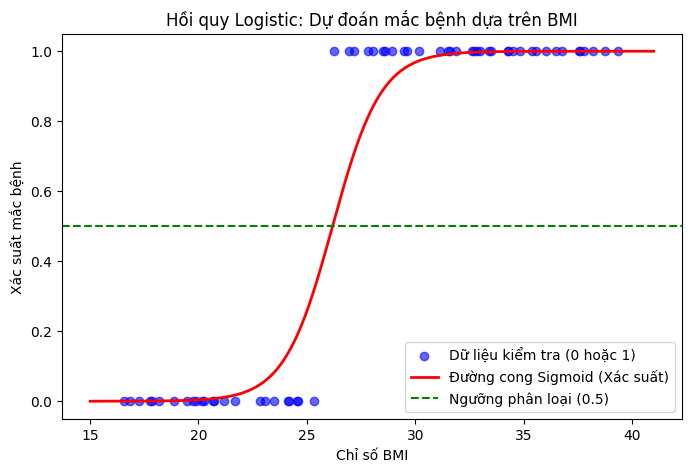

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Tạo dữ liệu mẫu giả lập dựa trên mối liên hệ logic (BMI cao -> dễ mắc bệnh)
np.random.seed(42)
n_patients = 300
bmi = np.random.uniform(16, 40, (n_patients, 1))

# Xác suất mắc bệnh tăng mạnh khi BMI vượt ngưỡng 25 (thừa cân/béo phì)
# Sử dụng hàm sigmoid kèm chút nhiễu ngẫu nhiên
z = 0.45 * (bmi - 26) + np.random.normal(0, 0.8, (n_patients, 1))
prob = 1 / (1 + np.exp(-z))
mac_benh = (prob >= 0.5).astype(int).ravel()  # 1: Mắc bệnh, 0: Không mắc bệnh

# Chia dữ liệu huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(bmi, mac_benh, test_size=0.2, random_state=42)

# 2 & 3. Xây dựng và huấn luyện mô hình Logistic Regression
log_model = LogisticRegression()
log_model.fit(X_train, y_train)

# 4. Dự đoán xác suất và nhãn trên tập kiểm tra
y_prob = log_model.predict_proba(X_test)[:, 1]  # Xác suất thuộc lớp 1 (Mắc bệnh)
y_pred = log_model.predict(X_test)              # Nhãn dự đoán (0 hoặc 1)

print("--- BÀI 2: DỰ ĐOÁN MẮC BỆNH THEO BMI ---")
for i in range(5):
    print(f"BMI: {X_test[i][0]:.1f} -> Xác suất bệnh: {y_prob[i]:.2f} | Dự đoán: {y_pred[i]} | Thực tế: {y_test[i]}")

# 5. Đánh giá mô hình
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print(f"\nĐộ chính xác (Accuracy): {acc:.4f}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(cm)

# 6. Trực quan hóa dữ liệu và đường hồi quy logistic
X_range = np.linspace(15, 41, 300).reshape(-1, 1)
y_sigmoid = log_model.predict_proba(X_range)[:, 1]

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color="blue", alpha=0.6, label="Dữ liệu kiểm tra (0 hoặc 1)")
plt.plot(X_range, y_sigmoid, color="red", linewidth=2, label="Đường cong Sigmoid (Xác suất)")
plt.axhline(0.5, color="green", linestyle="--", label="Ngưỡng phân loại (0.5)")
plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.title("Hồi quy Logistic: Dự đoán mắc bệnh dựa trên BMI")
plt.legend()
plt.show()

# **Bài 3**

In [5]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải bộ dữ liệu thực tế California Housing
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = housing.target  # Giá nhà trung bình (đơn vị: 100,000 USD)

print("5 dòng đầu của dữ liệu:")
print(X.head())

# 2. Kiểm tra dữ liệu khuyết thiếu (Tiền xử lý)
print("\nSố lượng giá trị null từng cột:\n", X.isnull().sum())

# 3. Chia dữ liệu thành tập huấn luyện (80%) và tập kiểm tra (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Khởi tạo và huấn luyện mô hình Linear Regression
model_real = LinearRegression()
model_real.fit(X_train, y_train)

# 5. Dự đoán và đánh giá mô hình
y_pred = model_real.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R^2 Score: {r2:.4f}")

5 dòng đầu của dữ liệu:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Số lượng giá trị null từng cột:
 MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---
Mean Squared Error (MSE): 0.5559
R^2 Score: 0.5758
